# Pair 2 — Gemma 4 E4B evaluation

**Amazon product search (ESCI dataset)**

I evaluate Gemma 4 E4B on the same 400 classification cases and 33 ranking queries as Qwen3.5-4B. The tasks are ESCI classification and product ranking. The GGUF model runs locally through llama.cpp without fine-tuning.


## 1. Setup

I use llama-server to keep Gemma loaded in memory between requests. Running llama-cli separately for each of the 433 evaluation requests would repeatedly reload the model, increasing the total execution time.

Run the following command from the project root:

llama-server -m "Models\Pair_02\models\Gemma\gemma-4-E4B_q4_0-it.gguf" -c 4096 -ngl 99 --host 127.0.0.1 --port 8081

Keep the server running while executing the notebook.


In [1]:
from pathlib import Path
import json
import re
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# Find Pair_02 from the notebook folder or project root
folder = Path.cwd().resolve()
PAIR = next((p for p in [folder, folder / "Models/Pair_02", folder.parent / "Models/Pair_02"]
             if (p / "datasets/classification_cases.csv").exists()), None)
if PAIR is None:
    raise FileNotFoundError("Could not find Models/Pair_02/datasets/classification_cases.csv")

DATA = PAIR / "datasets"
OUT = PAIR / "results/Gemma"
OUT.mkdir(parents=True, exist_ok=True)

SERVER = "http://127.0.0.1:8081"
RUN_FULL = True
SEED = 42

classification = pd.read_csv(DATA / "classification_cases.csv", dtype={"query_id": str, "product_id": str})
ranking = pd.read_csv(DATA / "ranking_cases.csv", dtype={"query_id": str, "product_id": str})
classification = classification.fillna("")
ranking = ranking.fillna("")

print("Classification cases:", len(classification))
print("Ranking queries:", ranking["query_id"].nunique())
print("ESCI distribution:\n", classification["esci_label"].value_counts())

Classification cases: 400
Ranking queries: 33
ESCI distribution:
 esci_label
I    100
C    100
S    100
E    100
Name: count, dtype: int64


## 2. Run Gemma

I use the same product information, prompt templates, output rules and scoring procedures as the Qwen evaluation. ESCI labels are never shown to the model in the prompt.


In [2]:
# Check which model is running before evaluation
r = requests.get(SERVER + "/v1/models", timeout=10)
r.raise_for_status()
model_ids = [str(x.get("id", "")) for x in r.json().get("data", [])]
print("Connected to:", model_ids)
assert any("gemma" in model.lower() for model in model_ids), "Start the Gemma server, not Qwen"

def ask_gemma(prompt, max_tokens=128):
    payload = {
        "messages": [
            {"role": "system", "content": "Return only the requested answer. Do not explain."},
            {"role": "user", "content": prompt},
        ],
        "temperature": 0,
        "max_tokens": max_tokens,
        "chat_template_kwargs": {"enable_thinking": False},
        "stream": False,
    }
    start = time.perf_counter()
    response = requests.post(SERVER + "/v1/chat/completions", json=payload, timeout=300)
    response.raise_for_status()
    answer = response.json()["choices"][0]["message"]["content"] or ""
    return answer.strip(), time.perf_counter() - start

# Recognise only clear ESCI labels

def parse_label(text):
    if not text:
        return "INVALID"
    text = text.strip().upper()
    match = re.fullmatch(
        r"(?:LABEL:\s*)?([ESCI])(?:\s*:\s*(?:EXACT|SUBSTITUTE|COMPLEMENT|IRRELEVANT|[ESCI]))?\.?",
        text,
    )
    if match:
        return match.group(1)
    return {"EXACT": "E", "SUBSTITUTE": "S", "COMPLEMENT": "C", "IRRELEVANT": "I"}.get(text, "INVALID")


def parse_order(text, n=10):
    matches = re.findall(r"(?is)RANKING\s*:\s*\[([0-9,\s]+)\]", text)
    if not matches:
        return None
    ids = [int(x) for x in re.findall(r"\d+", matches[-1])]
    return ids if len(ids) == n and set(ids) == set(range(1, n + 1)) else None


Connected to: ['Models\\Pair_02\\models\\Gemma\\gemma-4-E4B_q4_0-it.gguf']


In [3]:
def class_prompt(row):
    return (
        "Classify this product for the customer's search query.\n"
        "E = Exact match, S = Substitute, C = Complement, I = Irrelevant.\n"
        "Return one line only, exactly like LABEL: E\n\n"
        f"Query: {row['query']}\n"
        f"Product title: {row['product_title']}\n"
        f"Description: {str(row['product_description'])[:500]}"
    )

# Save after every case so the experiment can be resumed
class_file = OUT / "classification_predictions.csv"
old = pd.read_csv(class_file, dtype={"example_id": str}) if class_file.exists() else pd.DataFrame()
completed = set(old["example_id"].astype(str)) if "example_id" in old else set()

subset = classification if RUN_FULL else classification.head(10)
rows = old.to_dict("records")

for i, (_, case) in enumerate(subset.iterrows(), 1):
    example_id = str(case["example_id"])
    if example_id in completed:
        continue
    try:
        answer, seconds = ask_gemma(class_prompt(case))
        prediction = parse_label(answer)
        error = "" if prediction != "INVALID" else "Invalid label format"
    except Exception as e:
        answer, seconds, prediction, error = "", np.nan, "INVALID", str(e)

    rows.append({
        "example_id": example_id, "query_id": case["query_id"],
        "true_label": case["esci_label"], "predicted_label": prediction,
        "time_seconds": seconds, "raw_response": answer, "error": error
    })
    pd.DataFrame(rows).to_csv(class_file, index=False)
    print(f"Classification {i}/{len(subset)}: {prediction}")

class_results = pd.read_csv(class_file)
print("Saved:", class_file, "| Rows:", len(class_results))

Classification 1/400: E
Classification 2/400: I
Classification 3/400: E
Classification 4/400: I
Classification 5/400: E
Classification 6/400: C
Classification 7/400: S
Classification 8/400: S
Classification 9/400: S
Classification 10/400: S
Classification 11/400: C
Classification 12/400: S
Classification 13/400: S
Classification 14/400: C
Classification 15/400: I
Classification 16/400: S
Classification 17/400: C
Classification 18/400: I
Classification 19/400: I
Classification 20/400: S
Classification 21/400: I
Classification 22/400: S
Classification 23/400: I
Classification 24/400: S
Classification 25/400: S
Classification 26/400: S
Classification 27/400: E
Classification 28/400: I
Classification 29/400: I
Classification 30/400: I
Classification 31/400: S
Classification 32/400: E
Classification 33/400: I
Classification 34/400: S
Classification 35/400: S
Classification 36/400: E
Classification 37/400: E
Classification 38/400: S
Classification 39/400: E
Classification 40/400: E
Classific

## 3. Product ranking

I give Gemma 10 candidate products for each customer query. It must return an ordering of the product numbers. The labels are only used afterwards to calculate ranking quality.

In [4]:
def rank_prompt(group):
    query = group.iloc[0]["query"]
    products = []
    for i, (_, p) in enumerate(group.iterrows(), 1):
        products.append(f"{i}. {p['product_title']} | {str(p['product_description'])[:180]}")
    return (
        "Rank these 10 products from most to least relevant to the customer's query.\n"
        "Use each number 1 to 10 exactly once. Return one line only in this format:\n"
        "RANKING: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]\n\n"
        f"Query: {query}\n" + "\n".join(products)
    )

rank_file = OUT / "ranking_predictions.csv"
old = pd.read_csv(rank_file, dtype={"query_id": str}) if rank_file.exists() else pd.DataFrame()
completed = set(old["query_id"].astype(str)) if "query_id" in old else set()

all_groups = [(str(qid), g.reset_index(drop=True)) for qid, g in ranking.groupby("query_id", sort=False)]
groups = all_groups if RUN_FULL else all_groups[:2]
rows = old.to_dict("records")

for i, (query_id, group) in enumerate(groups, 1):
    if query_id in completed:
        continue
    if len(group) != 10:
        print("Skipping", query_id, "because it does not have 10 candidates")
        continue
    try:
        answer, seconds = ask_gemma(rank_prompt(group), max_tokens=100)
        order = parse_order(answer)
        error = "" if order else "Invalid ranking format"
    except Exception as e:
        answer, seconds, order, error = "", np.nan, None, str(e)

    rows.append({
        "query_id": query_id, "query": group.iloc[0]["query"],
        "candidate_ids": json.dumps(group["product_id"].astype(str).tolist()),
        "true_labels": json.dumps(group["esci_label"].astype(str).tolist()),
        "predicted_order": json.dumps(order) if order else "",
        "time_seconds": seconds, "raw_response": answer, "error": error,
    })
    pd.DataFrame(rows).to_csv(rank_file, index=False)
    print(f"Ranking {i}/{len(groups)}: {'OK' if order else 'INVALID'}")

rank_results = pd.read_csv(rank_file, dtype={"query_id": str})
print("Saved:", rank_file, "| Queries:", len(rank_results))

Ranking 1/33: OK
Ranking 2/33: OK
Ranking 3/33: OK
Ranking 4/33: OK
Ranking 5/33: OK
Ranking 6/33: OK
Ranking 7/33: OK
Ranking 8/33: OK
Ranking 9/33: OK
Ranking 10/33: OK
Ranking 11/33: OK
Ranking 12/33: OK
Ranking 13/33: OK
Ranking 14/33: OK
Ranking 15/33: OK
Ranking 16/33: OK
Ranking 17/33: OK
Ranking 18/33: OK
Ranking 19/33: OK
Ranking 20/33: OK
Ranking 21/33: OK
Ranking 22/33: OK
Ranking 23/33: OK
Ranking 24/33: OK
Ranking 25/33: OK
Ranking 26/33: OK
Ranking 27/33: OK
Ranking 28/33: OK
Ranking 29/33: OK
Ranking 30/33: OK
Ranking 31/33: OK
Ranking 32/33: OK
Ranking 33/33: OK
Saved: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_02\results\Gemma\ranking_predictions.csv | Queries: 33


## 4. Results

I report classification accuracy and Macro F1, along with NDCG@10 and MRR@10 for ranking. An Exact match counts as relevant for MRR. For NDCG, I use gains E=3, S=2, C=1, I=0.

I also report invalid outputs because following instructions matters for an automated shopping system.

Total: 400 | Valid: 400 | Invalid: 0
Accuracy (valid responses): 0.48
Macro F1 (valid responses): 0.459
Accuracy (invalid counted as wrong): 0.48
              precision    recall  f1-score   support

           E       0.53      0.72      0.61       100
           S       0.37      0.48      0.42       100
           C       0.39      0.16      0.23       100
           I       0.61      0.56      0.58       100

    accuracy                           0.48       400
   macro avg       0.47      0.48      0.46       400
weighted avg       0.47      0.48      0.46       400



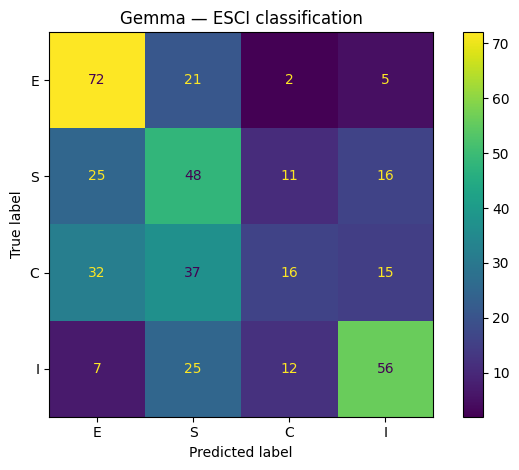

Average response time: 0.17 seconds


In [5]:
# Classification scores
class_results = pd.read_csv(class_file)
valid = class_results[class_results["predicted_label"].isin(list("ESCI"))]
labels = ["E", "S", "C", "I"]

print("Total:", len(class_results), "| Valid:", len(valid), "| Invalid:", len(class_results) - len(valid))
if len(valid):
    print("Accuracy (valid responses):", round(accuracy_score(valid["true_label"], valid["predicted_label"]), 3))
    print("Macro F1 (valid responses):", round(f1_score(valid["true_label"], valid["predicted_label"], labels=labels, average="macro", zero_division=0), 3))
    print("Accuracy (invalid counted as wrong):", round((class_results["true_label"] == class_results["predicted_label"]).mean(), 3))
    print(classification_report(valid["true_label"], valid["predicted_label"], labels=labels, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(valid["true_label"], valid["predicted_label"], labels=labels)
    plt.title("Gemma — ESCI classification")
    plt.tight_layout()
    plt.savefig(OUT / "confusion_matrix.png", dpi=150)
    plt.show()

print("Average response time:", round(class_results["time_seconds"].mean(), 2), "seconds")

In [6]:
def dcg(values):
    values = np.asarray(values, dtype=float)
    return float(np.sum((2 ** values - 1) / np.log2(np.arange(2, len(values) + 2))))

def rank_metrics(row):
    try:
        order = json.loads(row["predicted_order"])
        labels = json.loads(row["true_labels"])
        if sorted(order) != list(range(1, 11)):
            raise ValueError("Invalid order")
        scores = {"E": 3, "S": 2, "C": 1, "I": 0}
        gains = [scores[x] for x in labels]
        ranked = [gains[x - 1] for x in order]
        ideal = dcg(sorted(gains, reverse=True))
        ndcg = dcg(ranked) / ideal if ideal else np.nan
        mrr = next((1 / i for i, x in enumerate(order, 1) if labels[x - 1] == "E"), 0)
        return pd.Series({"ndcg_at_10": ndcg, "mrr_at_10": mrr})
    except (ValueError, TypeError, KeyError):
        return pd.Series({"ndcg_at_10": np.nan, "mrr_at_10": np.nan})

rank_results = pd.read_csv(rank_file)
scores = rank_results.apply(rank_metrics, axis=1)
rank_results = pd.concat([rank_results, scores], axis=1)
rank_results.to_csv(OUT / "ranking_metrics.csv", index=False)

print("Ranking queries:", len(rank_results))
print("Valid rankings:", rank_results["ndcg_at_10"].notna().sum())
print("Mean NDCG@10:", round(rank_results["ndcg_at_10"].mean(), 3))
print("Mean MRR@10:", round(rank_results["mrr_at_10"].mean(), 3))
print("Average response time:", round(rank_results["time_seconds"].mean(), 2), "seconds")
display(rank_results[["query_id", "ndcg_at_10", "mrr_at_10", "time_seconds", "error"]].head(10))

Ranking queries: 33
Valid rankings: 33
Mean NDCG@10: 0.857
Mean MRR@10: 0.557
Average response time: 0.7 seconds


,query_id,ndcg_at_10,mrr_at_10,time_seconds,error
0,954,0.703161,0.166667,0.504473,NaN
1,1503,0.904012,0.500000,0.541606,NaN
2,1612,0.819138,0.166667,0.667892,NaN
3,6416,0.838705,0.100000,0.863919,NaN
4,6865,0.904012,0.500000,0.809199,NaN
5,10841,0.992078,1.000000,0.718691,NaN
6,11924,1.000000,1.000000,0.572649,NaN
7,11925,0.795118,0.142857,0.629093,NaN
8,13045,0.695149,0.125000,0.711878,NaN
9,23600,0.932111,1.000000,0.693320,NaN


## 5. Notes

I will compare Gemma with Qwen on the exact same examples in `Comparison.ipynb`. I will examine errors in the ESCI classes, difficult ranking queries, invalid outputs and response time.

This uses a quantised local model. The classification sample is balanced and ranking queries were deliberately filtered, so the results are limited to these evaluation settings.
